# Bibliotecas permitidas

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Criação de banco de dados artificial para regressão

In [4]:
n = 100 # Definir a quantidade de amostras do banco de dados sintético

In [5]:
df = []
df.append([])
df.append([])
for i in range(n):
  # Cria os dados sintéticos randomizando um pouco o X e o Y
  df[0].append(i + ((np.random.rand()-.5)*50))
  df[1].append(i*10 + ((np.random.rand()-.5)*50))

# Perceptron em si

In [6]:
data_in = df[0].copy()
for i in range(len(data_in)):
  data_in[i] = [data_in[i], 1]
data_out = df[1].copy()

In [7]:
weigths = np.random.rand(2) #Coeficiente angular e bias/coeficiente linear
weigths -= .5 #balanceado +-

In [8]:
def linear_function(x):
  return weigths[0] * x + weigths[1] #Função linear manualmente construída com base nos pesos

In [9]:
def generic_linear_function(x):
  return np.matmul(x, np.transpose(weigths)) #Tentativa de automatizar como seria feito com funções genéricas recursivas

In [10]:
def activation_function(data_in): #Literalmente uma camada de abstração inútil que seria só para escolher qual função usar caso eu fosse usar mais funções nesse código
  result = generic_linear_function(data_in)
  return result

In [11]:
y_pred_pre = [] #Predição inicial com fatores aleatorios
for i in range(n):
  y_pred_pre.append(activation_function(data_in[i]))

# Treinamento

In [12]:
learning_rate = 0.000001
epochs = 100

In [13]:
def hebbian(y, w, d_in, d_out, learning_rate): #Nome errado
  for i in range(len(y)):
    w[0] -= learning_rate * d_in[i] * (y[i] - d_out[i]) #Formula do aprendizado
    w[1] -= learning_rate * (y[i] - d_out[i])

In [14]:
def generic_hebbian(y, w, d_in, d_out, learning_rate): #Nome errado
  for i in range(len(y)):
    for j in range(len(w)):
      w[j] -= learning_rate * d_in[i][j] * (y[i] - d_out[i])

In [15]:
def train(y_pred, weights, data_in, data_out, epochs, learning_rate):
  for e in range(epochs):
    hebbian(y_pred, weights, data_in, data_out, learning_rate)
    y_pred = []
    for i in range(len(data_in)):
      y_pred.append(activation_function(data_in[i]))
  return y_pred

In [16]:
def generic_train(y_pred, weights, data_in, data_out, epochs, learning_rate):
  for e in range(epochs):
    generic_hebbian(y_pred, weights, data_in, data_out, learning_rate)
    y_pred = []
    for i in range(len(data_in)):
      y_pred.append(activation_function(data_in[i]))
  return y_pred

In [17]:
y_pred = generic_train(y_pred_pre, weigths, data_in, data_out, epochs, learning_rate)

In [18]:
def plot_recursion(data_in, data_out, y_pred):
  plt.scatter(data_in, data_out)
  plt.plot(data_in, y_pred, color="orange")
  plt.show()

In [19]:
def plot_generic_recursion(x_axis, y_real, y_pred):
  plt.scatter(x_axis, y_real)
  plt.plot(x_axis, y_pred, color="orange")
  plt.show()

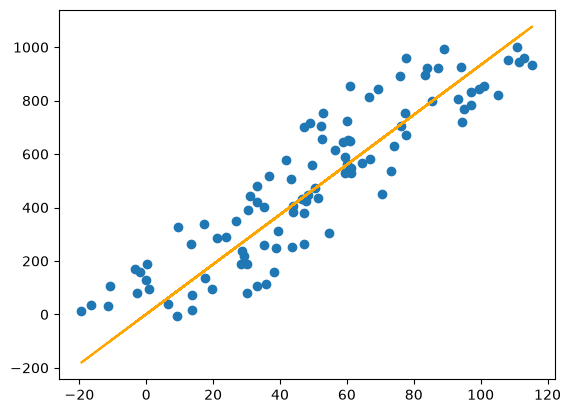

In [20]:
plot_generic_recursion(df[0], df[1], y_pred)

# Métricas

In [21]:
error = 0
sum = 0
for i in range(len(data_in)):
  error += (data_out[i] - y_pred[i])
  #error_relative += abs((y_pred[i] - data_out[i])/data_out[i])
  sum += data_out[i]
error /= len(data_in)
error_relative = error/(sum/len(data_in))
print ("Mean Absolute Error:", error)
print ("Mean Relative Error", error_relative)

Mean Absolute Error: 26.116571663130404
Mean Relative Error 0.05294759397048485
